<a href="https://colab.research.google.com/github/vnltam2003-lgtm/Store_Info/blob/main/F115143127_%E6%AD%A6%E7%8E%89%E7%8E%B2%E5%BF%83.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 步驟 1：設定隨機組子 (Seed Everything)
設定 Python、NumPy 與 PyTorch 的隨機種子，以確保實驗結果具備可重複性 (Reproducibility)。

In [2]:
import torch
import numpy as np
import random
import os

def seed_everything(seed):
    """Sets random seeds for reproducibility."""
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# 步驟 2：掛載 Google 雲端硬碟
將 Google 雲端硬碟掛載到 Colab 執行環境中，以便直接讀取儲存在雲端硬碟中的資料集壓縮檔。

In [3]:
from google.colab import drive
drive.mount('/gdrive')

Mounted at /gdrive


# 步驟 3：尋找雲端硬碟中的壓縮檔
掃描雲端硬碟目錄，列出所有的 `.zip` 檔案，以確保專案資料集壓縮檔已正確放置。

In [5]:
import os

drive_path = '/gdrive/My Drive'
if os.path.exists(drive_path):
    zip_files = [f for f in os.listdir(drive_path) if f.endswith('.zip')]
    print("在雲端硬碟中找到的 .zip 檔案列表：")
    for zip_file in zip_files:
        print(f"- {zip_file}")
else:
    print("找不到雲端硬碟路徑，請確認是否已成功掛載 /gdrive")

在雲端硬碟中找到的 .zip 檔案列表：
- 115-1-nkust-iem-midterm.zip


# 步驟 4：解壓縮資料集並自動定位路徑
將本地端的資料集壓縮檔解壓至 `/content/dataset_local` 目錄，並自動偵測及定位 `train.csv` 的檔案路徑。

In [7]:
import os
import zipfile

# Dataset ZIP path / 資料集壓縮檔路徑
zip_path = '/gdrive/My Drive/115-1-nkust-iem-midterm.zip'

# Extraction directory / 解壓縮目錄
extract_target_dir = '/content/dataset_local'

# Check whether the ZIP exists / 確認壓縮檔是否存在
if not os.path.isfile(zip_path):
    raise FileNotFoundError(
        f"ZIP file not found / 找不到壓縮檔：{zip_path}"
    )

# Extract the dataset / 解壓縮資料集
print("Extracting dataset... / 正在解壓縮資料集……")

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_target_dir)

print("Extraction completed! / 解壓縮完成！")

# Find the label CSV / 尋找標籤 CSV 檔案
csv_path = None
folder_path = None

for root, dirs, files in os.walk(extract_target_dir):
    if 'train_labels.csv' in files:
        csv_path = os.path.join(root, 'train_labels.csv')
        folder_path = root
        break

if csv_path is None:
    raise FileNotFoundError(
        "train_labels.csv not found / 找不到 train_labels.csv"
    )

print("Dataset directory / 資料集目錄：", folder_path)
print("Label CSV path / 標籤檔案路徑：", csv_path)

Extracting dataset... / 正在解壓縮資料集……
Extraction completed! / 解壓縮完成！
Dataset directory / 資料集目錄： /content/dataset_local/期中專案資料集
Label CSV path / 標籤檔案路徑： /content/dataset_local/期中專案資料集/train_labels.csv


In [8]:
import pandas as pd

# Read image labels / 讀取影像標籤
df = pd.read_csv(csv_path)

print("Columns / 欄位名稱：", df.columns.tolist())
print("Total rows / 總筆數：", len(df))

# Display the first five rows / 顯示前五筆資料
display(df.head())

Columns / 欄位名稱： ['id', 'label']
Total rows / 總筆數： 12000


,id,label
0,train_00001.png,0
1,train_00002.png,1
2,train_00003.png,0
3,train_00004.png,0
4,train_00005.png,0


# 步驟 5：定義自訂 Image Dataset 類別與切分 Train/Val
建立 `CustomImageDataset` 類別讀取影像。若 CSV 中無 `split` 欄位，程式會自動以 8:2 的比例隨機切分訓練集 (Train) 與驗證集 (Val)，並正確與影像路徑對齊。

In [9]:
import os
import pandas as pd
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# 為了保證讀取正常，我們先檢查 CSV 的欄位並進行 train/val 切分
class CustomImageDataset(Dataset):
    def __init__(self, csv_file, root_dir, split='train', transform=None, random_state=42):
        self.df_all = pd.read_csv(csv_file)
        self.root_dir = root_dir
        self.split = split
        self.transform = transform

        # 偵測欄位名稱 (有些資料集可能是 'class', 'label', 'Category' 等)
        label_col = 'class' if 'class' in self.df_all.columns else ('label' if 'label' in self.df_all.columns else self.df_all.columns[1])
        id_col = 'unique_id' if 'unique_id' in self.df_all.columns else ('id' if 'id' in self.df_all.columns else self.df_all.columns[0])

        # 若 CSV 沒有 'split' 欄位，我們自己手動切分 80% train / 20% val
        if 'split' not in self.df_all.columns:
            from sklearn.model_selection import train_test_split
            train_df, val_df = train_test_split(self.df_all, test_size=0.2, random_state=random_state, stratify=self.df_all[label_col])
            if split == 'train':
                self.df = train_df.reset_index(drop=True)
            else:
                self.df = val_df.reset_index(drop=True)
        else:
            self.df = self.df_all[self.df_all['split'] == split].reset_index(drop=True)

        self.classes = sorted(self.df_all[label_col].unique())
        self.class_to_idx = {cls_name: idx for idx, cls_name in enumerate(self.classes)}

        self.valid_indices = []
        self.resolved_paths = {}

        # 建立實體檔案索引：遞迴掃描 root_dir 底下的所有檔案
        file_db = {}
        print(f"正在掃描實體資料夾 {self.root_dir} ...")
        if os.path.exists(self.root_dir):
            for root, dirs, files in os.walk(self.root_dir):
                for f in files:
                    name_without_ext, _ = os.path.splitext(f)
                    key = name_without_ext.lower().strip()
                    file_db[key] = os.path.join(root, f)
        else:
            print(f"錯誤：找不到路徑 {self.root_dir}")

        # 開始進行 CSV 清單與實體檔案的對應
        print(f"開始解析 [{split}] 集合的 CSV 清單...")
        for idx, row in self.df.iterrows():
            raw_id = str(row[id_col]).replace('\\', '/')
            base_name = os.path.basename(raw_id)
            name_without_ext, _ = os.path.splitext(base_name)
            csv_key = name_without_ext.lower().strip()

            if csv_key in file_db:
                self.valid_indices.append(idx)
                self.resolved_paths[idx] = file_db[csv_key]

        print(f"[{split}] 原始清單數量: {len(self.df)} 筆，實際比對成功影像數量: {len(self.valid_indices)} 筆")

    def __len__(self):
        return len(self.valid_indices)

    def __getitem__(self, idx):
        actual_idx = self.valid_indices[idx]
        row = self.df.iloc[actual_idx]
        img_path = self.resolved_paths[actual_idx]

        image = Image.open(img_path).convert('RGB')
        label_col = 'class' if 'class' in self.df.columns else ('label' if 'label' in self.df.columns else self.df.columns[1])
        label = self.class_to_idx[row[label_col]]

        if self.transform:
            image = self.transform(image)

        return image, label

# 設定影像的前處理
data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 重新建立 Dataset 與 DataLoader
train_dataset = CustomImageDataset(csv_file=csv_path, root_dir=folder_path, split='train', transform=data_transforms)
val_dataset = CustomImageDataset(csv_file=csv_path, root_dir=folder_path, split='val', transform=data_transforms)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

try:
    images, labels = next(iter(train_loader))
    print(f"\n成功讀取一個 Batch 的訓練資料！")
    print(f"影像張量形狀: {images.shape}")
    print(f"標籤張量形狀: {labels.shape}")
except Exception as e:
    print(f"\n讀取錯誤: {e}")

正在掃描實體資料夾 /content/dataset_local/期中專案資料集 ...
開始解析 [train] 集合的 CSV 清單...
[train] 原始清單數量: 9600 筆，實際比對成功影像數量: 9600 筆
正在掃描實體資料夾 /content/dataset_local/期中專案資料集 ...
開始解析 [val] 集合的 CSV 清單...
[val] 原始清單數量: 2400 筆，實際比對成功影像數量: 2400 筆

成功讀取一個 Batch 的訓練資料！
影像張量形狀: torch.Size([32, 3, 224, 224])
標籤張量形狀: torch.Size([32])


# 步驟 6：原始影像視覺化展示
從資料載入器 (DataLoader) 中取出一個批次的資料，還原標準化設定並繪製出來，以直觀檢查影像與標籤是否對齊正確。

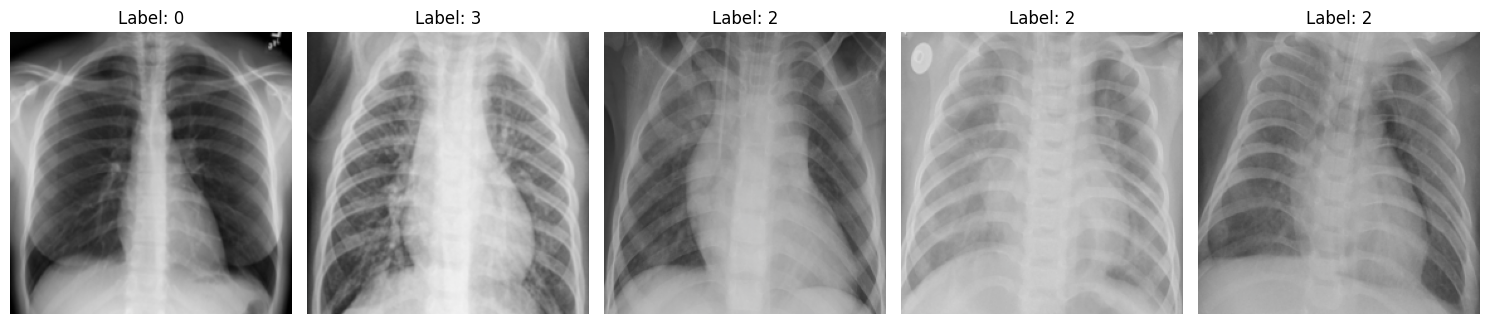

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# 1. 取得類別索引對照表的反向映射
idx_to_class = {v: k for k, v in train_dataset.class_to_idx.items()}

# 2. 定義還原 PyTorch Normalize 影像並顯示的函數
def imshow(img, title=None):
    img = img.numpy().transpose((1, 2, 0)) # 轉換維度 [C, H, W] -> [H, W, C]
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean # 還原標準化
    img = np.clip(img, 0, 1)
    plt.imshow(img)
    if title is not None:
        plt.title(title, fontsize=12)
    plt.axis('off')

# 3. 取出部分影像進行視覺化展示
try:
    images, labels = next(iter(train_loader))
    num_images_to_show = min(len(images), 5) # 顯示最多 4 張圖片

    plt.figure(figsize=(15, 5))
    for i in range(num_images_to_show):
        plt.subplot(1, num_images_to_show, i + 1)
        class_name = idx_to_class[labels[i].item()]
        imshow(images[i], title=f"Label: {class_name}")

    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f"視覺化顯示時發生錯誤: {e}")

# 步驟 7：進行資料擴增 (Data Augmentation) 與建立 Dataloader
針對訓練集設計資料擴增策略（如隨機裁切、水平翻轉、隨機旋轉與顏色變換），並套用至 `CustomImageDataset`，最後重新建立 Dataloader。

In [11]:
import os
import pandas as pd
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# 設定圖片尺寸大小
IMG_SIZE = 224

# 1. 定義 Train Set 的資料擴增轉換
train_transforms = transforms.Compose([
    # 隨機 resize 並裁剪 (Crop) 圖片至指定大小
    transforms.RandomResizedCrop(IMG_SIZE),
    # 隨機水平翻轉 (p=0.5)
    transforms.RandomHorizontalFlip(p=0.5),
    # 隨機旋轉（正負15度內）
    transforms.RandomRotation(degrees=15),
    # 顏色隨機變換：亮度、對比度、飽和度、色調
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    # 轉換為 PyTorch Tensor
    transforms.ToTensor(),
    # 正規化圖片 (使用 ImageNet 的標準平均值與標準差)
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. 定義 Validation Set 的轉換 (僅進行縮放與標準化，不作擴增變形)
val_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 3. 重新建立訓練集與驗證集的 Dataset，並套用不同的 transforms
train_dataset = CustomImageDataset(csv_file=csv_path, root_dir=folder_path, split='train', transform=train_transforms)
val_dataset = CustomImageDataset(csv_file=csv_path, root_dir=folder_path, split='val', transform=val_transforms)

# 4. 建立 DataLoader
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

# 測試加載一個 Batch
try:
    images, labels = next(iter(train_loader))
    print("成功載入資料擴增後的訓練資料集！")
    print(f"一個 Batch 的影像維度: {images.shape}")
    print(f"一個 Batch 的標籤維度: {labels.shape}")
except Exception as e:
    print(f"載入資料時發生錯誤: {e}")

正在掃描實體資料夾 /content/dataset_local/期中專案資料集 ...
開始解析 [train] 集合的 CSV 清單...
[train] 原始清單數量: 9600 筆，實際比對成功影像數量: 9600 筆
正在掃描實體資料夾 /content/dataset_local/期中專案資料集 ...
開始解析 [val] 集合的 CSV 清單...
[val] 原始清單數量: 2400 筆，實際比對成功影像數量: 2400 筆
成功載入資料擴增後的訓練資料集！
一個 Batch 的影像維度: torch.Size([32, 3, 224, 224])
一個 Batch 的標籤維度: torch.Size([32])


# 步驟 8：展示資料擴增後的影像
從完成資料擴增的載入器中隨機取出 10 張影像進行繪製，觀察旋轉、翻轉與顏色抖動等效果是否套用成功。

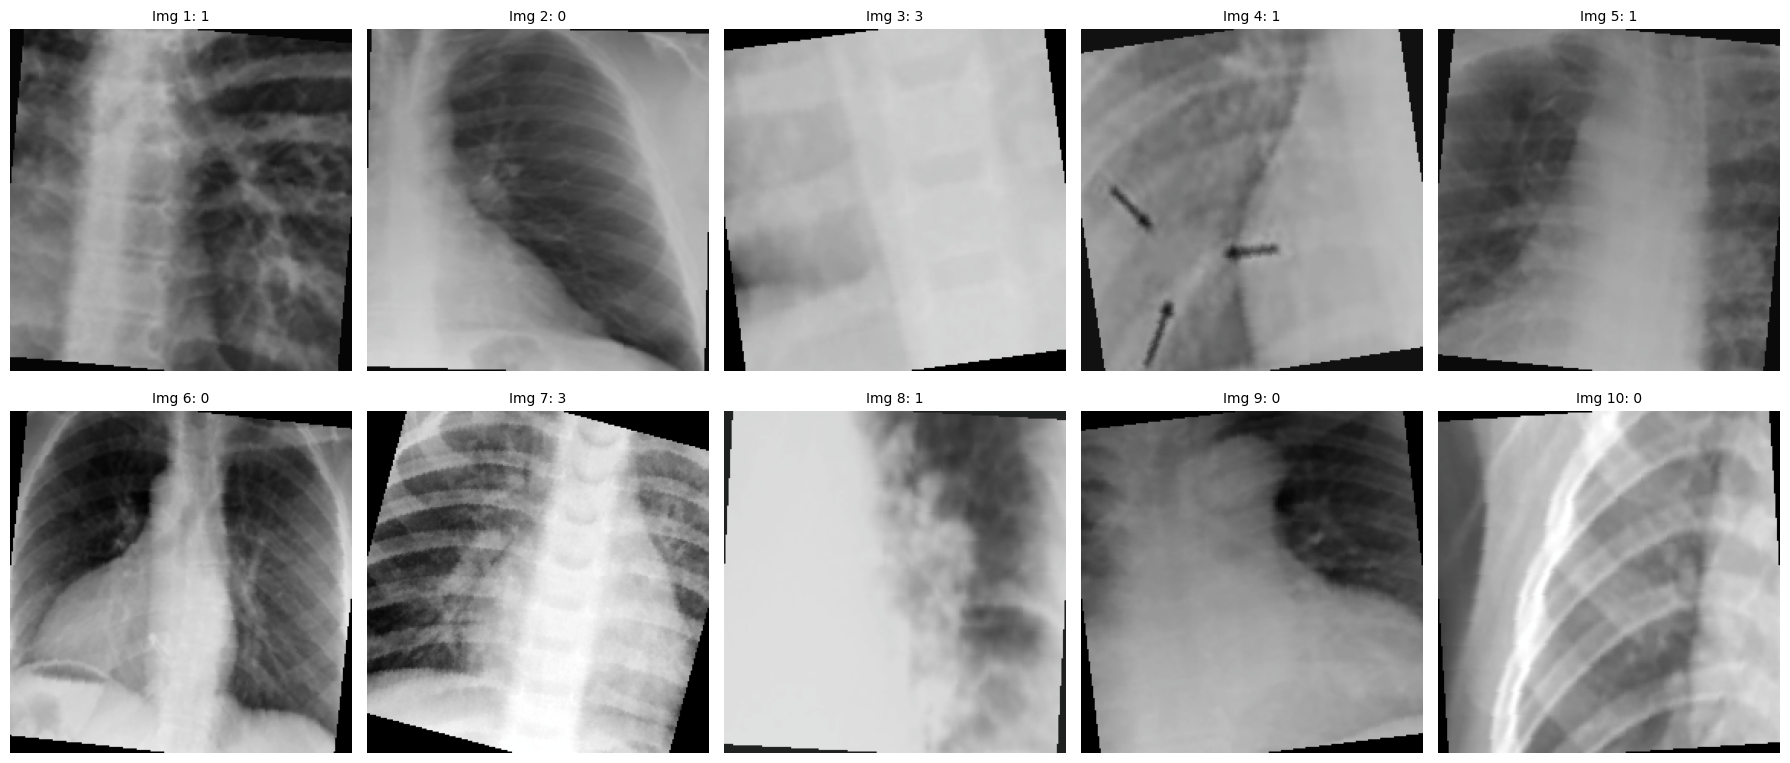

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# 1. 取得類別索引對照表的反向映射
idx_to_class = {v: k for k, v in train_dataset.class_to_idx.items()}

# 2. 定義還原 PyTorch Normalize 影像並顯示的函數
def imshow(img, title=None):
    img = img.numpy().transpose((1, 2, 0))  # 轉換維度 [C, H, W] -> [H, W, C]
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean  # 還原標準化
    img = np.clip(img, 0, 1)
    plt.imshow(img)
    if title is not None:
        plt.title(title, fontsize=10)
    plt.axis('off')

# 3. 取出 10 張資料擴增後的影像進行視覺化展示
try:
    # 由於 batch_size=32，一個 Batch 內足夠我們取得 10 張影像
    images, labels = next(iter(train_loader))
    num_images_to_show = 10

    # 設定畫布為 2 列 5 行的網格格式
    plt.figure(figsize=(18, 8))
    for i in range(num_images_to_show):
        plt.subplot(2, 5, i + 1)
        class_name = idx_to_class[labels[i].item()]
        imshow(images[i], title=f"Img {i+1}: {class_name}")

    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f"視覺化資料擴增影像時發生錯誤: {e}")

In [13]:
import torch

# Check GPU availability / 檢查 GPU 是否可用
print("GPU available / GPU 是否可用：", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name / GPU 名稱：", torch.cuda.get_device_name(0))
else:
    print("GPU not enabled / 尚未啟用 GPU")

GPU available / GPU 是否可用： True
GPU name / GPU 名稱： Tesla T4


# 步驟 9：初始化 VGG16 模型與微調訓練 (Fine-tuning)
下載預訓練的 VGG16 架構，將最後一層全連接層修改為 4 個輸出類別。設定 Adam 優化器與 CrossEntropy 損失函數，並開始進行 3 個 Epochs 的模型訓練。

In [14]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from torch.utils.data import DataLoader

# 1. 固定隨機種子以確保結果可重複性
seed_everything(42)

# 2. 重新設定 batch_size = 16 建立 DataLoader
BATCH_SIZE = 16
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# 3. 建立 VGG16 模型並修改最後一類全連接層（共有 4 類）
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
num_classes = len(train_dataset.classes)

print("正在下載與初始化 VGG16 模型...")
vgg16 = models.vgg16(pretrained=True)
# 替換最後的分類層以符合我們的 4 個分類標籤
num_features = vgg16.classifier[6].in_features
vgg16.classifier[6] = nn.Linear(num_features, num_classes)
vgg16 = vgg16.to(device)

# 4. 設定損失函數與優化器
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(vgg16.parameters(), lr=1e-4)

# 5. 開始訓練 3 個 Epochs，並且每 10 個 mini-batch 輸出一次 training loss
epochs = 3
print(f"\n開始訓練模型 (總共 {epochs} 個 Epochs, 裝置: {device})...")

for epoch in range(epochs):
    vgg16.train()
    running_loss = 0.0
    epoch_corrects = 0
    epoch_total = 0

    for batch_idx, (inputs, labels) in enumerate(train_loader):
        inputs = inputs.to(device)
        labels = labels.to(device)

        # 梯度歸零
        optimizer.zero_grad()

        # 前向傳播與計算 Loss
        outputs = vgg16(inputs)
        loss = criterion(outputs, labels)

        # 反向傳播與權重更新
        loss.backward()
        optimizer.step()

        # 統計資訊
        running_loss += loss.item()
        _, preds = torch.max(outputs, 1)
        epoch_corrects += torch.sum(preds == labels.data).item()
        epoch_total += inputs.size(0)

        # 每 10 個 mini-batch 輸出一次即時狀態
        if (batch_idx + 1) % 10 == 0:
            avg_mini_batch_loss = running_loss / 10
            print(f"Epoch [{epoch+1}/{epochs}], Batch [{batch_idx+1}/{len(train_loader)}] - Mini-Batch Loss: {avg_mini_batch_loss:.4f}")
            running_loss = 0.0

    # 計算每個 Epoch 的平均正確率
    train_acc = epoch_corrects / epoch_total
    print(f"=== Epoch {epoch+1} 完成！訓練集準確率 (Train Acc): {train_acc:.4f} ===\n")

正在下載與初始化 VGG16 模型...


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:08<00:00, 63.7MB/s]



開始訓練模型 (總共 3 個 Epochs, 裝置: cuda)...
Epoch [1/3], Batch [10/600] - Mini-Batch Loss: 1.1895
Epoch [1/3], Batch [20/600] - Mini-Batch Loss: 0.9184
Epoch [1/3], Batch [30/600] - Mini-Batch Loss: 0.8264
Epoch [1/3], Batch [40/600] - Mini-Batch Loss: 0.7792
Epoch [1/3], Batch [50/600] - Mini-Batch Loss: 1.0681
Epoch [1/3], Batch [60/600] - Mini-Batch Loss: 0.8512
Epoch [1/3], Batch [70/600] - Mini-Batch Loss: 0.8580
Epoch [1/3], Batch [80/600] - Mini-Batch Loss: 0.7717
Epoch [1/3], Batch [90/600] - Mini-Batch Loss: 0.6663
Epoch [1/3], Batch [100/600] - Mini-Batch Loss: 0.7561
Epoch [1/3], Batch [110/600] - Mini-Batch Loss: 0.8751
Epoch [1/3], Batch [120/600] - Mini-Batch Loss: 0.6617
Epoch [1/3], Batch [130/600] - Mini-Batch Loss: 0.6218
Epoch [1/3], Batch [140/600] - Mini-Batch Loss: 0.6030
Epoch [1/3], Batch [150/600] - Mini-Batch Loss: 0.7149
Epoch [1/3], Batch [160/600] - Mini-Batch Loss: 0.6544
Epoch [1/3], Batch [170/600] - Mini-Batch Loss: 0.6537
Epoch [1/3], Batch [180/600] - Mini-B

# 步驟 10：驗證集評估與混淆矩陣繪製
將模型切換至評估模式 (`eval()`)，預測驗證集 (Validation Set) 中的所有數據，輸出詳細的分類報告 (Classification Report) 並繪製混淆矩陣。

開始評估驗證集...

=== 驗證集評估完成 ===
驗證集總數量: 2400 筆
驗證集準確率 (Val Accuracy): 0.8492

詳細分類報告:
              precision    recall  f1-score   support

           0       0.84      0.96      0.90      1152
           1       0.99      0.66      0.80       576
           2       0.91      0.80      0.85       440
           3       0.64      0.84      0.73       232

    accuracy                           0.85      2400
   macro avg       0.84      0.82      0.82      2400
weighted avg       0.87      0.85      0.85      2400



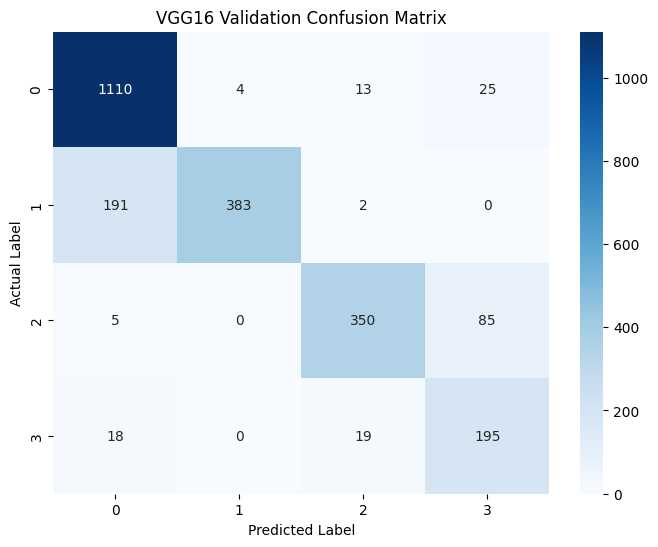

In [15]:
import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 將模型設定為評估模式
vgg16.eval()

all_preds = []
all_labels = []

print("開始評估驗證集...")
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = vgg16(inputs)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 計算驗證集準確率
all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
val_accuracy = np.mean(all_preds == all_labels)

print(f"\n=== 驗證集評估完成 ===")
print(f"驗證集總數量: {len(all_labels)} 筆")
print(f"驗證集準確率 (Val Accuracy): {val_accuracy:.4f}\n")

# 輸出分類報告 (Classification Report) - 確保 target_names 皆為字串
class_names = [str(c) for c in train_dataset.classes]
print("詳細分類報告:")
print(classification_report(all_labels, all_preds, target_names=class_names))

# 繪製混淆矩陣 (Confusion Matrix)
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('VGG16 Validation Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

# 步驟 11：計算驗證集 Macro-F1 分數
使用 scikit-learn 計算驗證集上的 Macro-F1 分數，作為評估模型多分類綜合效能的核心指標。

In [16]:
from sklearn.metrics import f1_score

# 計算驗證集的 Macro-F1 分數
macro_f1 = f1_score(all_labels, all_preds, average='macro')

print(f"驗證集上的 Macro-F1 分數 (Macro-F1 Score on Val): {macro_f1:.4f}")

驗證集上的 Macro-F1 分數 (Macro-F1 Score on Val): 0.8170


# 步驟 12：測試集影像推論與生成 submission.csv
載入範例提交檔 `sample_submission.csv`，遞迴讀取 `test` 資料夾中的實體影像，使用訓練好的 VGG16 進行推論，最終生成 `submission.csv`。

In [18]:
import pandas as pd
from google.colab import files

# Check submission format / 檢查提交檔格式
submission = pd.read_csv('/content/submission.csv')
sample = pd.read_csv(sample_sub_path)

assert submission.columns.tolist() == sample.columns.tolist()
assert len(submission) == 3000
assert submission['id'].equals(sample['id'])
assert not submission.isna().any().any()
assert submission['label'].isin([0, 1, 2, 3]).all()

print("Submission format passed! / 提交檔格式檢查通過！")

# Download submission / 下載提交檔
files.download('/content/submission.csv')

Submission format passed! / 提交檔格式檢查通過！


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
import os
import pandas as pd
import torch
from PIL import Image
from torchvision import transforms
from tqdm import tqdm

# 1. 定義測試集影像目錄與 sample_submission.csv 路徑
test_dir = os.path.join(folder_path, 'test') if 'folder_path' in globals() else '/content/dataset_local/期中專案資料集/test'
sample_sub_path = os.path.join(folder_path, 'sample_submission.csv') if 'folder_path' in globals() else '/content/dataset_local/期中專案資料集/sample_submission.csv'

print(f"測試集目錄路徑: {test_dir}")
print(f"範例提交檔路徑: {sample_sub_path}")

if not os.path.exists(test_dir):
    # 防呆機制：若不存在，掃描同級目錄下的 test 資料夾
    test_dir = '/content/dataset_local/期中專案資料集/test'

# 2. 讀取 sample_submission.csv
df_sub = pd.read_csv(sample_sub_path)
print(f"範例提交檔資料量: {len(df_sub)} 筆")

# 3. 定義測試集前處理轉換 (與 Validation 相同，不含 Data Augmentation)
test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 4. 掃描測試集目錄下的所有實體檔案建立字典，便於根據 ID 快速比對
test_files_db = {}
if os.path.exists(test_dir):
    for root, _, files in os.walk(test_dir):
        for f in files:
            name_without_ext, _ = os.path.splitext(f)
            # 去除空白並轉小寫作為 key
            test_files_db[name_without_ext.lower().strip()] = os.path.join(root, f)
else:
    print(f"錯誤：找不到測試集目錄 {test_dir}")

# 5. 開始預測
vgg16.eval()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
predictions = []

print("開始進行測試集推論預測...")
for idx, row in tqdm(df_sub.iterrows(), total=len(df_sub)):
    # 讀取 row 中的唯一識別碼 (通常是 id 或 unique_id 欄位)
    id_col = 'unique_id' if 'unique_id' in df_sub.columns else ('id' if 'id' in df_sub.columns else df_sub.columns[0])
    file_id = str(row[id_col]).replace('\\', '/')
    base_name = os.path.basename(file_id)
    name_without_ext, _ = os.path.splitext(base_name)
    csv_key = name_without_ext.lower().strip()

    # 取得影像實體路徑
    img_path = test_files_db.get(csv_key)

    if img_path and os.path.exists(img_path):
        try:
            image = Image.open(img_path).convert('RGB')
            tensor = test_transforms(image).unsqueeze(0).to(device)

            with torch.no_grad():
                outputs = vgg16(tensor)
                _, pred_idx = torch.max(outputs, 1)

            # 直接預測數值型 Label (0, 1, 2, 3)
            predictions.append(pred_idx.item())
        except Exception as e:
            print(f"讀取或預測圖片 {file_id} 時出錯: {e}")
            predictions.append(0)  # 若出錯，填入預設值
    else:
        # 找不到檔案時，預設填入 0
        predictions.append(0)

# 6. 將預測結果寫回 DataFrame
label_col = 'class' if 'class' in df_sub.columns else ('label' if 'label' in df_sub.columns else df_sub.columns[1])
df_sub[label_col] = predictions

# 7. 儲存至本地端根目錄 /content/submission.csv
submission_out_path = '/content/submission.csv'
df_sub.to_csv(submission_out_path, index=False)
print(f"\n=== submission.csv 生成成功！ ===")
print(f"已儲存至：{submission_out_path}")

# 8. 顯示前 5 筆資料確認
display(df_sub.head())

測試集目錄路徑: /content/dataset_local/期中專案資料集/test
範例提交檔路徑: /content/dataset_local/期中專案資料集/sample_submission.csv
範例提交檔資料量: 3000 筆
開始進行測試集推論預測...


100%|██████████| 3000/3000 [01:05<00:00, 45.50it/s]


=== submission.csv 生成成功！ ===
已儲存至：/content/submission.csv


,id,label
0,test_0001.png,3
1,test_0002.png,0
2,test_0003.png,2
3,test_0004.png,1
4,test_0005.png,0
